# Equivariant Graph Neural Networks

This notebook is part of the lab semiar [Machine Learning and AI in the Life Sciences: Methods and Applications](https://www.fu-berlin.de/vv/de/lv/935203) at Freie Universität Berlin.

In this practical we will again derive a graph convolutional network and employ it to predict of the electric dipole moment of QM9 molecules. However, this time we will add the atom positions to the set of input features. Other than the categorial features, 3D positions live in a vector space that exhibits symmetries. Indeed, molecular properties do not depend on the orientation or location of the molecule so that we expect a regression model to be invariant under rotation and translation.

## Setup environment

Let's install the required python packages. We will be working with the [`jax` library](https://docs.jax.dev/en/latest/index.html) and its ecosystem of deep learning tools.

In [ ]:
%%capture
!pip install ipdb
!pip install jax jraph flax optax torch-geometric

# QM9 Dataset

We will work with the QM9 dataset that is a benchmark database used in machine learning for molecular properties. It contains data for 133k small organic molecules with 19 regression targets. We can use the PyG libraray to load the molecules as graphs equpped with a number of pre-computed features:

**Atom features (`G.x`)** - $\mathbb{R}^{|V| \times 11}$
- 1st-5th features: Atom type (one-hot: H, C, N, O, F)
- 6th feature (also `data.z`): Atomic number (number of protons).
- 7th feature: Aromatic (binary)
- 8th-10th features: Electron orbital hybridization (one-hot: sp, sp2, sp3)
- 11th feature: Number of hydrogens

**Edge Index (`G.edge_index`)** - $\mathbb{R}^{2×|E|}$
- A tensor of dimensions 2 x `G.num_edges` that describe the edge connectivity of the graph

**Edge features (`G.edge_attr`)** - $\mathbb{R}^{|E|\times 4}$
- 1st-4th features: bond type (one-hot: single, double, triple, aromatic)

**Atom positions (`G.pos`)** - $\mathbb{R}^{|V|\times 3}$
- 3D coordinates of each atom.

**Target (`G.y`)** - $\mathbb{R}^{19}$

| Target | Property                      | Unit         | Description                                              |
|--------|-------------------------------|--------------|----------------------------------------------------------|
| 0      | $\mu$                         | D            | Dipole moment                                            |
| 1      | $\alpha$                      | $a_0^3$      | Isotropic polarizability                                |
| 2      | $\epsilon_{\textrm{HOMO}}$    | eV           | Highest occupied molecular orbital energy                |
| 3      | $\epsilon_{\textrm{LUMO}}$    | eV           | Lowest unoccupied molecular orbital energy               |
| 4      | $\Delta \epsilon$             | eV           | Gap between $\epsilon_{\textrm{HOMO}}$ and $\epsilon_{\textrm{LUMO}}$ |
| 5      | $\langle R^2 \rangle$         | $a_0^2$      | Electronic spatial extent                                |
| 6      | ZPVE                          | eV           | Zero point vibrational energy                            |
| 7      | $U_0$                         | eV           | Internal energy at 0K                                    |
| 8      | $U$                           | eV           | Internal energy at 298.15K                               |
| 9      | $H$                           | eV           | Enthalpy at 298.15K                                      |
| 10     | $G$                           | eV           | Free energy at 298.15K                                   |
| 11     | $c_{\textrm{v}}$              | cal/mol·K    | Heat capacity at 298.15K                                 |
| 12     | $U_0^{\textrm{ATOM}}$         | eV           | Atomization energy at 0K                                 |
| 13     | $U^{\textrm{ATOM}}$           | eV           | Atomization energy at 298.15K                            |
| 14     | $H^{\textrm{ATOM}}$           | eV           | Atomization enthalpy at 298.15K                          |
| 15     | $G^{\textrm{ATOM}}$           | eV           | Atomization free energy at 298.15K                       |
| 16     | $A$                           | GHz          | Rotational constant                                      |
| 17     | $B$                           | GHz          | Rotational constant                                      |
| 18     | $C$                           | GHz          | Rotational constant                                      |



In [ ]:
from typing import NamedTuple

import torch
from torch_geometric.datasets import QM9
import torch_geometric.transforms as T
from torch_geometric.utils import remove_self_loops

import numpy as np
import jax
import jax.numpy as jnp

class SetTarget(NamedTuple):
    target: int = 0
    """
    Only keep the label for a specific target (there are 19 targets in QM9).
    """
    def __call__(self, data):
        data.y = data.y[:, self.target]
        return data

# Transforms which are applied during data loading:
transform = SetTarget(0)

# Define our dataset, using torch datasets
qm9_dataset = QM9('./qm9/', transform=transform)
print(f"Total number of samples: {len(qm9_dataset)}.")

# Split datasets (subset of full dataset for efficiency)
train_dataset = qm9_dataset[:1000]
val_dataset = qm9_dataset[1000:2000]
test_dataset = qm9_dataset[2000:3000]
print(f"Created dataset splits with {len(train_dataset)} training, {len(val_dataset)} validation, {len(test_dataset)} test samples.")


Extracting qm9/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


Total number of samples: 130831.
Created dataset splits with 1000 training, 1000 validation, 1000 test samples.


## Representing atom positions

Let's add the atom positions to the `jraph.GraphsTuple` representation. To this end, we introduce a `NamedTuple` called `Feature` that holds both quatities in seperate variables (`x` and `p`). `NameTuple` subclasses are natively hanled by `jax` and work seamlessly (automatomatic differentiation, just in time compilation, etc.).

In [ ]:
import torch_geometric
from typing import List, Generator
from torch.utils.data import DataLoader, default_collate

import jraph

BATCH_SIZE = 32
MAX_NUM_NODES = 29
MAX_NUM_EDGES = 56
TYPE = jnp.float32

class Feature(NamedTuple):
  x: jnp.ndarray
  p: jnp.ndarray

def jraph_iterate(data: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
  for G in data:
    nodes = Feature(
        x=jnp.asarray(G.x, dtype=TYPE),
        p=jnp.asarray(G.pos, dtype=TYPE))
    yield jraph.GraphsTuple(
      n_node=jnp.asarray([G.num_nodes]),
      n_edge=jnp.asarray([G.num_edges]),
      nodes=nodes,
      edges=jnp.ones(G.num_edges, dtype=TYPE),
      globals=jnp.asarray([G.y], dtype=TYPE),
      senders=jnp.asarray(G.edge_index[0]),
      receivers=jnp.asarray(G.edge_index[1]))

def jraph_collate(batch: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
  """
  Collate function specifies how to combine a list of data samples into a batch.
  """
  return next(jraph.dynamically_batch(
        jraph_iterate(batch),
        n_node=BATCH_SIZE  * MAX_NUM_NODES + 1, # Plus one for the extra padding node.
        n_edge=BATCH_SIZE  * MAX_NUM_EDGES,
        n_graph=BATCH_SIZE + 1))

# Create pytorch data loader with custom collate function
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, collate_fn=jraph_collate, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=jraph_collate, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, collate_fn=jraph_collate, shuffle=False)

# Invariant graph convolutional layer


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement a graph convolution module that incorporates the atom positions when updating the features (`G.nodes.x`). Design the module such that the output is invariant under rigid motions of the molecule.
> * Create and run a unit test that checks the invariance of your module

In [ ]:
import flax.linen as nn
from typing import Callable

class InvariantGraphConvolution(nn.Module):
    psi: nn.Module
    phi: nn.Module

    @nn.compact
    def __call__(self, G):
        x = G.nodes.x          # shape: (num_nodes, node_feat_dim)
        p = G.nodes.p          # shape: (num_nodes, 3)
        senders = G.senders    # shape: (num_edges,)
        receivers = G.receivers # shape: (num_edges,)
        edges = G.edges

        # Compute pairwise squared distances for edges
        p_senders = p[senders]  # [num_edges, 3]
        p_receivers = p[receivers]
        rel_dist2 = jnp.sum((p_senders - p_receivers)**2, axis=-1, keepdims=True)

        # Gather x for senders/receivers
        x_senders = x[senders]
        x_receivers = x[receivers]

        # Edge messages m_ij
        m_ij = self.psi(jnp.concatenate([x_senders, x_receivers, rel_dist2, edges[:, None]], axis=-1))

        # Aggregate messages
        m_sum = jax.ops.segment_sum(m_ij, receivers, x.shape[0])

        # Node update
        x_new = self.phi(jnp.concatenate([x, m_sum], axis=-1))

        return G._replace(nodes=Feature(x_new, p))

In [ ]:
def test_invariant_layer(layer, params, G):
    # Using numpy for rotation and translation
    import numpy as np
    from scipy.spatial.transform import Rotation as R

    # Make random rotation and translation
    rot = R.random()
    R_matrix = rot.as_matrix()
    translation = np.random.normal(size=(1, 3))

    # Get original positions
    p = np.asarray(G.nodes.p)
    # Apply transformation
    p_trans = (R_matrix @ p.T).T + translation

    # Build new nodes with original features, transformed positions
    import jax.numpy as jnp
    G_trans = G._replace(nodes=Feature(G.nodes.x, jnp.asarray(p_trans, dtype=G.nodes.p.dtype)))

    # Forward pass
    out_orig = layer.apply(params, G)
    out_trans = layer.apply(params, G_trans)

    # Compare
    assert np.allclose(
        np.asarray(out_orig.nodes.x),
        np.asarray(out_trans.nodes.x),
        atol=1e-5
    ), "FAIL: Not invariant!"
    print("PASS: Layer is invariant under rotation and translation.")


In [ ]:
sample_graph = next(jraph_iterate([train_dataset[0]]))
psi = nn.Dense(8)
phi = nn.Dense(8)
layer = InvariantGraphConvolution(psi=psi, phi=phi)
rng = jax.random.PRNGKey(0)
params = layer.init(rng, sample_graph)

test_invariant_layer(layer, params, sample_graph)

PASS: Layer is invariant under rotation and translation.


# Equivariant graph convolutional layer


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement a graph convolution module that updates the atom features and positions. Design the module such that the features and positions are invariant and equivariant under rigid motions, respectively.
> * Create and run a unit test that checks the in-/equivariance of your module

In [ ]:
import flax.linen as nn
from typing import Callable

class EquivariantGraphConvolution(nn.Module):
    psi: nn.Module
    phi: nn.Module

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
        x = G.nodes.x           # [n_nodes, d_x]
        p = G.nodes.p           # [n_nodes, 3]
        senders = G.senders     # [n_edges]
        receivers = G.receivers # [n_edges]
        edges = G.edges         # [n_edges, edge_attr_dim] or [n_edges]

        # 1. Edge features
        p_senders = p[senders]
        p_receivers = p[receivers]
        rel_dist2 = jnp.sum((p_senders - p_receivers) ** 2, axis=-1, keepdims=True)
        x_senders = x[senders]
        x_receivers = x[receivers]

        edge_input = jnp.concatenate([x_senders, x_receivers, rel_dist2, edges[:, None]], axis=-1)

        # 2. Compute message and position update coefficient per edge
        psi_out = self.psi(edge_input)        # [n_edges, d_m + 1]
        m_ij = psi_out[:, :-1]                # [n_edges, d_m]
        q_coef_ij = psi_out[:, -1:]
        q_coef_ij = jnp.tanh(q_coef_ij) * 0.01           # [n_edges, 1]

        # 3. Feature update: aggregate m_ij for each node
        m_sum = jax.ops.segment_sum(m_ij, receivers, x.shape[0])   # [n_nodes, d_m]
        h_i = self.phi(jnp.concatenate([x, m_sum], axis=-1))       # [n_nodes, d_x]
        h_i = nn.LayerNorm()(h_i)
        # 4. Position update: sum over messages with q_coef_ij
        delta_p = p_senders - p_receivers          # [n_edges, 3]
        update = delta_p * q_coef_ij               # [n_edges, 3]
        neighbor_count = jax.ops.segment_sum(jnp.ones_like(receivers), receivers, p.shape[0])
        neighbor_count = jnp.maximum(neighbor_count, 1.0).reshape(-1, 1)  # avoid division by zero
        update_sum = jax.ops.segment_sum(update, receivers, p.shape[0])    # [n_nodes, 3]
        p_new = p + update_sum / neighbor_count     # [n_nodes, 3]

        return G._replace(nodes=Feature(h_i, p_new))

In [ ]:
def test_equivariant_layer(layer, params, G):
    import numpy as np
    from scipy.spatial.transform import Rotation as R
    import jax.numpy as jnp

    # Build random rotation and translation
    rot = R.random()
    R_matrix = rot.as_matrix()      # (3,3)
    translation = np.random.normal(size=(1, 3))  # (1,3)

    # Apply rotation and translation to original positions
    p = np.asarray(G.nodes.p)
    p_trans = (R_matrix @ p.T).T + translation    # (num_nodes, 3)
    # Convert back to jnp
    p_trans = jnp.asarray(p_trans, dtype=p.dtype)
    G_trans = G._replace(nodes=Feature(G.nodes.x, p_trans))

    # Run layer on both
    out_orig = layer.apply(params, G)
    out_trans = layer.apply(params, G_trans)

    # 1. Invariance: Features
    x1 = np.asarray(out_orig.nodes.x)
    x2 = np.asarray(out_trans.nodes.x)
    assert np.allclose(x1, x2, atol=1e-5), "FAIL: Features are not invariant!"

    # 2. Equivariance: Positions
    p1 = np.asarray(out_orig.nodes.p)
    p2 = np.asarray(out_trans.nodes.p)
    # Apply same rotation/translation to original output positions
    p1_rot = (R_matrix @ p1.T).T + translation
    assert np.allclose(p2, p1_rot, atol=1e-5), "FAIL: Positions are not equivariant!"

    print("PASS: Features are invariant and positions are equivariant under rotation and translation.")


In [ ]:
sample_graph = next(jraph_iterate([train_dataset[0]]))
psi = nn.Dense(9)
phi = nn.Dense(8)
layer = EquivariantGraphConvolution(psi=psi, phi=phi)
rng = jax.random.PRNGKey(0)
params = layer.init(rng, sample_graph)

test_equivariant_layer(layer, params, sample_graph)

PASS: Features are invariant and positions are equivariant under rotation and translation.


# Equivariant graph convolutional network


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement a graph neural network based on your equivariant and invariant convolutional layer that regresses the graph-level target `G.y`
> * Create and run a unit test that checks the invariance of your module


In [ ]:
class EquivariantGCN(nn.Module):
    num_layers: int
    hidden_size: int

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
        for _ in range(self.num_layers):
            G = EquivariantGraphConvolution(
                psi=nn.Dense(self.hidden_size+ 1), #+1 cause q
                phi=nn.Dense(self.hidden_size)
            )(G)



        G = InvariantGraphConvolution(psi=nn.Dense(self.hidden_size), phi=nn.Dense(self.hidden_size))(G)

        n_node = G.n_node
        x = G.nodes.x
        def get_graph_indices(n_node):
            return jnp.concatenate([jnp.full((n,), i) for i, n in enumerate(n_node)])

        node_graph_idx = get_graph_indices(n_node)
        graph_embedding = jraph.segment_mean(x, node_graph_idx, n_node.shape[0])

        return nn.Dense(1)(graph_embedding)

In [ ]:
def test_model_invariance(model, params, G):
    import numpy as np
    from scipy.spatial.transform import Rotation as R
    import jax.numpy as jnp

    rot = R.random()
    R_matrix = rot.as_matrix()
    translation = np.random.normal(size=(1, 3))

    p = np.asarray(G.nodes.p)
    p_trans = (R_matrix @ p.T).T + translation
    G_trans = G._replace(nodes=Feature(G.nodes.x, jnp.asarray(p_trans, dtype=p.dtype)))

    y_orig = model.apply(params, G)
    y_trans = model.apply(params, G_trans)
    assert np.allclose(np.asarray(y_orig), np.asarray(y_trans), atol=1e-5), "FAIL: Model output is not invariant!"
    print("PASS: Model output is invariant under translation and rotation.")

In [ ]:
sample_graph = next(jraph_iterate([train_dataset[0]]))
model = EquivariantGCN(num_layers=4, hidden_size=128)
rng = jax.random.PRNGKey(0)
params = model.init(rng, sample_graph)

test_model_invariance(model, params, sample_graph)


PASS: Model output is invariant under translation and rotation.


# Predicting the electric dipole moment


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Train your model on (a subset of) the QM9 dataset
> * evaluate the performance of your model


In [ ]:
import optax

for batch in train_loader:
    example_batch = batch
    break
model = EquivariantGCN(num_layers=4, hidden_size=128)
rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)
optimizer = optax.adam(1e-4) #or 1e-6 for smother loss decrease
opt_state = optimizer.init(params)

def loss_mse(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals.squeeze()
    return jnp.mean((preds.squeeze() - targets) ** 2)

def loss_mae(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals.squeeze()
    return jnp.mean(jnp.abs(preds.squeeze() - targets))

def loss_huber(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals.squeeze()
    return jnp.mean(optax.huber_loss(preds.squeeze(), targets))

def train_step(params, opt_state, batch, loss_fn):
    loss, grads = jax.value_and_grad(loss_fn)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss


In [ ]:
def train_model(loss_fn, num_epochs=20):
    params = model.init(rng, example_batch)
    opt_state = optimizer.init(params)
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        epoch_train_losses = []
        for batch in train_loader:
            params, opt_state, loss = train_step(params, opt_state, batch, loss_fn)
            epoch_train_losses.append(loss)
        train_loss = jnp.mean(jnp.array(epoch_train_losses))

        # Validation
        epoch_val_losses = []
        for batch in val_loader:
            val_loss = loss_fn(params, batch)
            epoch_val_losses.append(val_loss)
        val_loss = jnp.mean(jnp.array(epoch_val_losses))

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")

    return params, train_losses, val_losses

def eval_on_test(params, loss_fn):
    test_losses = []
    for batch in test_loader:
        test_loss = loss_fn(params, batch)
        test_losses.append(test_loss)
    print(f"Test Loss: {jnp.mean(jnp.array(test_losses)):.4f}")


Training with MSE loss
Epoch 1: Train Loss=2.4050, Val Loss=2.1469
Epoch 2: Train Loss=1.8755, Val Loss=2.1300
Epoch 3: Train Loss=1.8364, Val Loss=2.2597
Epoch 4: Train Loss=1.7876, Val Loss=1.9287
Epoch 5: Train Loss=1.7731, Val Loss=1.7545
Epoch 6: Train Loss=2.0860, Val Loss=2.3307
Epoch 7: Train Loss=1.7658, Val Loss=1.7976
Epoch 8: Train Loss=1.7011, Val Loss=1.6334
Epoch 9: Train Loss=1.7069, Val Loss=1.7590
Epoch 10: Train Loss=1.6607, Val Loss=1.9950
Epoch 11: Train Loss=1.6812, Val Loss=2.1454
Epoch 12: Train Loss=1.6261, Val Loss=1.5697
Epoch 13: Train Loss=1.6809, Val Loss=1.5660
Epoch 14: Train Loss=1.6281, Val Loss=1.5284
Epoch 15: Train Loss=1.5930, Val Loss=1.5450
Epoch 16: Train Loss=1.7233, Val Loss=1.6861
Epoch 17: Train Loss=1.5129, Val Loss=1.8047
Epoch 18: Train Loss=1.5414, Val Loss=1.8946
Epoch 19: Train Loss=1.4912, Val Loss=2.0344
Epoch 20: Train Loss=1.4643, Val Loss=1.7501
Test Loss: 1.2881


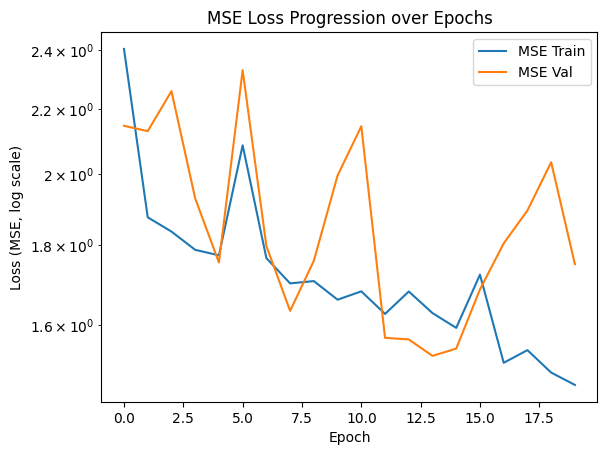


Training with MAE loss
Epoch 1: Train Loss=1.1182, Val Loss=1.0678
Epoch 2: Train Loss=1.0506, Val Loss=1.0478
Epoch 3: Train Loss=0.9972, Val Loss=1.1384
Epoch 4: Train Loss=0.9860, Val Loss=0.9763
Epoch 5: Train Loss=0.9929, Val Loss=0.9709
Epoch 6: Train Loss=0.9613, Val Loss=1.0213
Epoch 7: Train Loss=0.9494, Val Loss=0.9909
Epoch 8: Train Loss=0.9410, Val Loss=1.2074
Epoch 9: Train Loss=0.9617, Val Loss=0.9797
Epoch 10: Train Loss=0.9076, Val Loss=0.9639
Epoch 11: Train Loss=0.9227, Val Loss=1.1190
Epoch 12: Train Loss=0.9074, Val Loss=1.1970
Epoch 13: Train Loss=0.9143, Val Loss=0.9271
Epoch 14: Train Loss=0.8833, Val Loss=0.9788
Epoch 15: Train Loss=0.9042, Val Loss=0.9175
Epoch 16: Train Loss=0.8647, Val Loss=0.9077
Epoch 17: Train Loss=0.8874, Val Loss=0.9879
Epoch 18: Train Loss=0.8576, Val Loss=0.9604
Epoch 19: Train Loss=0.8510, Val Loss=0.9281
Epoch 20: Train Loss=0.8403, Val Loss=0.9039
Test Loss: 0.7647


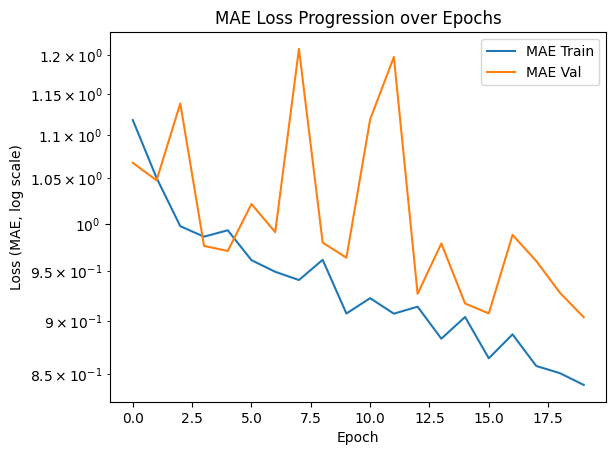


Training with Huber loss
Epoch 1: Train Loss=0.7609, Val Loss=0.6964
Epoch 2: Train Loss=0.6591, Val Loss=0.6306
Epoch 3: Train Loss=0.6295, Val Loss=0.8204
Epoch 4: Train Loss=0.6371, Val Loss=0.6589
Epoch 5: Train Loss=0.6222, Val Loss=0.5919
Epoch 6: Train Loss=0.6031, Val Loss=0.6213
Epoch 7: Train Loss=0.5743, Val Loss=0.6599
Epoch 8: Train Loss=0.5626, Val Loss=0.5718
Epoch 9: Train Loss=0.5651, Val Loss=0.6214
Epoch 10: Train Loss=0.5399, Val Loss=0.6499
Epoch 11: Train Loss=0.5456, Val Loss=0.5708
Epoch 12: Train Loss=0.5560, Val Loss=0.5643
Epoch 13: Train Loss=0.5380, Val Loss=0.5870
Epoch 14: Train Loss=0.5090, Val Loss=0.6225
Epoch 15: Train Loss=0.5208, Val Loss=0.5514
Epoch 16: Train Loss=0.5395, Val Loss=0.5565
Epoch 17: Train Loss=0.5035, Val Loss=0.5448
Epoch 18: Train Loss=0.4947, Val Loss=0.5381
Epoch 19: Train Loss=0.4969, Val Loss=0.5817
Epoch 20: Train Loss=0.4839, Val Loss=0.5972
Test Loss: 0.4905


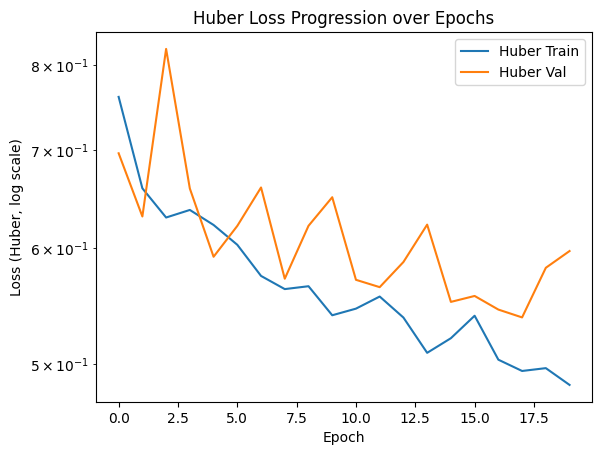

In [ ]:
import matplotlib.pyplot as plt

for loss_name, loss_fn in [
    ("MSE", loss_mse),
    ("MAE", loss_mae),
    ("Huber", loss_huber)
]:
    print(f"\nTraining with {loss_name} loss")
    params, train_losses, val_losses = train_model(loss_fn)
    eval_on_test(params, loss_fn)

    plt.plot(train_losses, label=f'{loss_name} Train')
    plt.plot(val_losses, label=f'{loss_name} Val')
    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel(f'Loss ({loss_name}, log scale)')
    plt.title(f"{loss_name} Loss Progression over Epochs")
    plt.legend()
    plt.show()